# Standalone East River Forward Model

This notebook walks through the East River hydrology + reactive-transport
forward run step by step — loading the data, building the model,
running the simulation, and examining the results.

All input data lives in this repository under `inputs/east_river/`.
No code or data outside the repo is needed.

In [1]:
import os
import sys
import pickle
import time
from pathlib import Path
from typing import Any, cast

import numpy as np
from numpy.typing import NDArray
import pandas as pd
from pandas import DataFrame, DatetimeIndex, Series
import torch
import matplotlib.pyplot as plt

# Make sure potions is importable (run from scripts/)
sys.path.insert(0, str(Path("../src").resolve()))
os.environ["POTIONS_COMPILE"] = "0"

import potions as pt
from potions.common_types import ForcingData, RtZoneConfiguration
from potions.reactive_transport import get_simple_carbon_adsorption_network
from potions.model_batched import BatchedConfig, run_hydro_rt_batched

## 1. Load the forcing + measured streamflow

The `PTQ.txt` file holds daily `(ppt, temp, q_meas)` and `EVAP.txt` holds
potential evapotranspiration — both as whitespace-separated text with dates
encoded as `YYYYMMDD` integers.

In [2]:
DATA_DIR = Path("../inputs/east_river")

ptq = pd.read_csv(
    DATA_DIR / "PTQ.txt",
    sep=r"\s+",
    skiprows=1,
    index_col=0,
    parse_dates=True,
    date_format="%Y%m%d",
)
pet = pd.read_csv(DATA_DIR / "EVAP.txt", sep=r"\s+")
ptq.index = pd.to_datetime(ptq.index)
pet.index = ptq.index
site = ptq.merge(pet, left_index=True, right_index=True, how="inner")
site.columns = ["ppt", "temp", "q_meas", "pet"]
site = site[["ppt", "temp", "pet", "q_meas"]]

print(
    f"Record: {site.index[0]:%Y-%m-%d} .. {site.index[-1]:%Y-%m-%d}  ({len(site)} days)"
)
site.head()

Record: 2014-10-01 .. 2021-09-30  (2557 days)


,ppt,temp,pet,q_meas
date,,,,
2014-10-01,0.000000,1.5,2.206979,1.288467
2014-10-02,13.033121,1.4,4.527629,1.236703
2014-10-03,0.000000,1.8,4.591441,1.107695
2014-10-04,1.727022,4.1,5.480709,1.036838
2014-10-05,0.000000,6.5,5.554541,0.991844


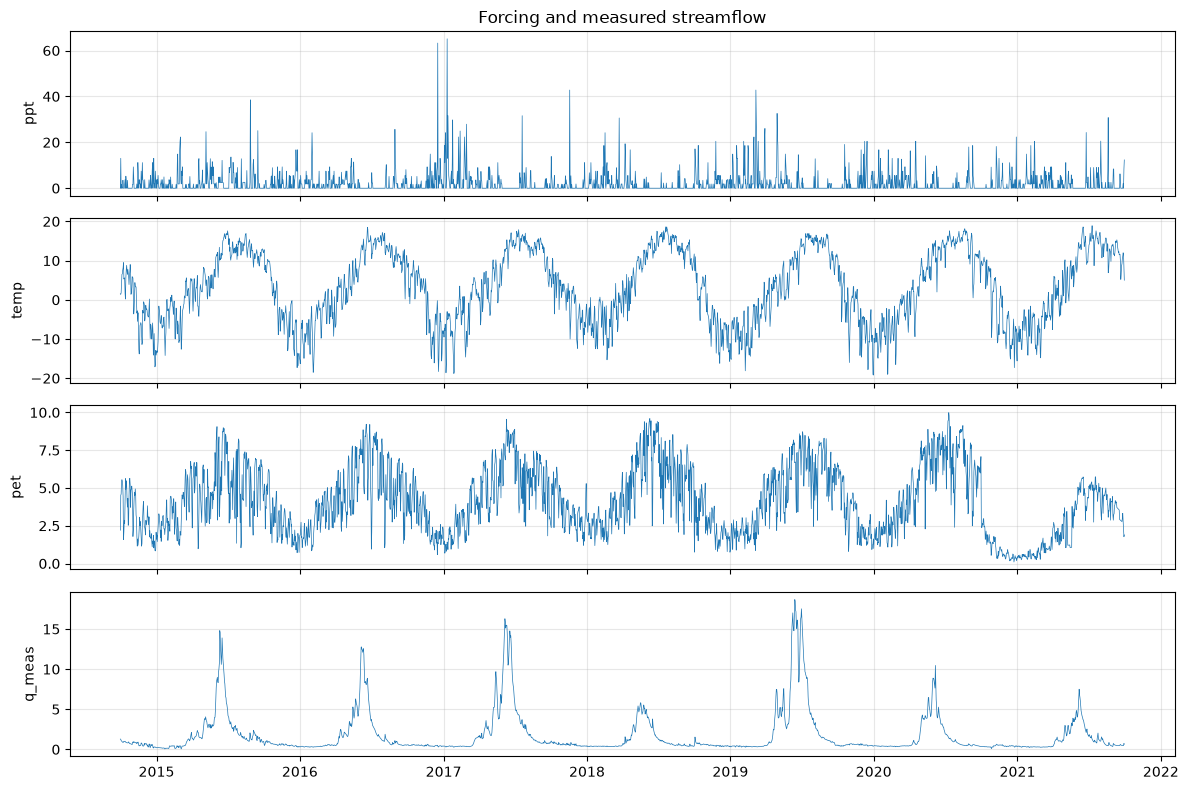

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, ["ppt", "temp", "pet", "q_meas"]):
    ax.plot(site.index, site[col], linewidth=0.5)
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)
axes[0].set_title("Forcing and measured streamflow")
plt.tight_layout()

## 2. Load the measured river DOC

The raw `er_phf0_npoc.csv` has `npoc` values in ng/kg; divide by
1000 (mg/L) and 12.01 (molar mass of carbon) to get mmol/L.  Duplicate
dates are averaged.

In [4]:
doc_raw = pd.read_csv(DATA_DIR / "er_phf0_npoc.csv", index_col=0, parse_dates=True)
doc_raw.index = pd.to_datetime(doc_raw.index)
doc_raw["npoc"] = pd.to_numeric(doc_raw["npoc"], errors="coerce")
doc = (doc_raw["npoc"] / 1000.0 / 12.01).rename("DOC")
doc = doc.groupby(doc.index).mean().to_frame()

print(
    f"DOC measurements: {len(doc)} days, {doc.index[0]:%Y-%m-%d} .. {doc.index[-1]:%Y-%m-%d}"
)
doc.describe()

DOC measurements: 1409 days, 2015-09-18 .. 2024-09-30


,DOC
count,1409.000000
mean,0.000090
std,0.000051
min,0.000000
25%,0.000054
50%,0.000072
75%,0.000114
max,0.000525


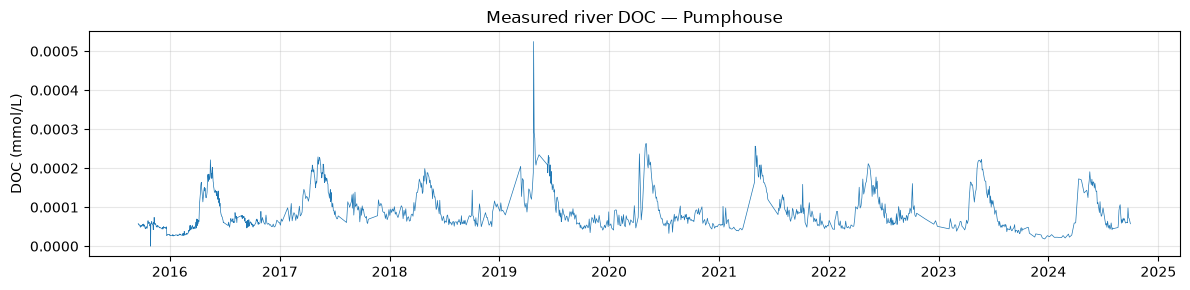

In [5]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(doc.index, doc["DOC"], linewidth=0.5)
ax.set_ylabel("DOC (mmol/L)")
ax.set_title("Measured river DOC — Pumphouse")
ax.grid(True, alpha=0.3)
plt.tight_layout()

## 3. The reaction network

The simple carbon-adsorption network shipped by potions-py:
4 aqueous species `DOC / SOC(s) / X- / XDOC`, 1 mineral
`SOC(s)`, exchange sites enabled.

In [6]:
network = get_simple_carbon_adsorption_network()
print(f"Species:       {network.species_names}")
print(f"Minerals:      {network.mineral_names}")
print(f"Has exchange:  {network.has_exchange}")
print(f"Num species:   {network.num_species}")
print(f"Num minerals:  {network.num_minerals}")

Species:       ['DOC', 'SOC(s)', 'X-', 'XDOC']
Minerals:      ['SOC(s)']
Has exchange:  True
Num species:   4
Num minerals:  1


## 4. The model structure

The HBV-lateral model has 8 zones in a snow → surface → shallow → deep
two-layer (hs/rp) arrangement.  The last zone of each layer is the river zone.

In [7]:
ZONES = (
    "snow_hs",
    "snow_rp",
    "surface_hs",
    "surface_rp",
    "shallow_hs",
    "shallow_rp",
    "deep_hs",
    "deep_rp",
)
SNOW_ZONES = frozenset(("snow_hs", "snow_rp"))

zone_configs = {
    name: RtZoneConfiguration(
        do_reactions=name not in SNOW_ZONES,
        do_speciation=name not in SNOW_ZONES,
    )
    for name in ZONES
}
print("Per-zone reactions + speciation:")
for name, cfg in zone_configs.items():
    print(
        f"  {name:20s}  do_reactions={cfg.do_reactions}  do_speciation={cfg.do_speciation}"
    )

Per-zone reactions + speciation:
  snow_hs               do_reactions=False  do_speciation=False
  snow_rp               do_reactions=False  do_speciation=False
  surface_hs            do_reactions=True  do_speciation=True
  surface_rp            do_reactions=True  do_speciation=True
  shallow_hs            do_reactions=True  do_speciation=True
  shallow_rp            do_reactions=True  do_speciation=True
  deep_hs               do_reactions=True  do_speciation=True
  deep_rp               do_reactions=True  do_speciation=True


## 5. The 85-parameter layout

The model is parameterised by 85 floats in calibration order:

| Block | Size | Description |
|-------|------|-------------|
| Hydro | 25 | HBV conceptual-hydrology parameters per zone |
| RT zone | 48 | Porous-medium properties + kinetic parameters per zone |
| Init state | 12 | Log10 mineral + exchange-site concentrations per reacting zone |

Snow zones carry 3 RT parameters (porosity, depth, passive water storage);
each of the 6 reacting zones carries 7 (the 3 porous-medium values plus
`sw_threshold`, `sw_exp`, `q_10`, `ssa`).
The mineral/exchange init columns are log10-valued and ordered per reacting
zone: `{zone}_soc` then `{zone}_x`.

In [8]:
# --- Hydrology block (25) ---
FIXED_ALPHA = {
    "shallow_hs.alpha": 1.0,
    "shallow_rp.alpha": 1.0,
    "deep_hs.alpha": 1.0,
    "deep_rp.alpha": 1.0,
}
hyd_bounds = dict(pt.HbvLateralModel.default_parameter_ranges())
for k, v in FIXED_ALPHA.items():
    hyd_bounds[k] = (v, v)
hyd_names = list(hyd_bounds.keys())
print(f"Hydro parameters ({len(hyd_names)}):")
for name in hyd_names:
    lo, hi = hyd_bounds[name]
    mid = 0.5 * (lo + hi)
    print(f"  {name:25s}  ({lo}, {hi})  midpoint={mid}")

Hydro parameters (25):
  snow_hs.tt                 (-1.0, 1.0)  midpoint=0.0
  snow_hs.fmax               (0.5, 5.0)  midpoint=2.75
  snow_rp.tt                 (-1.0, 1.0)  midpoint=0.0
  snow_rp.fmax               (0.5, 5.0)  midpoint=2.75
  surface_hs.fc              (50.0, 1000.0)  midpoint=525.0
  surface_hs.lp              (0.05, 1.0)  midpoint=0.525
  surface_hs.beta            (0.05, 5.0)  midpoint=2.525
  surface_hs.k0              (0.0, 1.0)  midpoint=0.5
  surface_hs.thr             (0.0, 1000.0)  midpoint=500.0
  surface_rp.fc              (50.0, 1000.0)  midpoint=525.0
  surface_rp.lp              (0.05, 1.0)  midpoint=0.525
  surface_rp.beta            (0.05, 5.0)  midpoint=2.525
  surface_rp.k0              (0.0, 1.0)  midpoint=0.5
  surface_rp.thr             (0.0, 1000.0)  midpoint=500.0
  shallow_hs.k               (-5.0, -1.0)  midpoint=-3.0
  shallow_hs.alpha           (1.0, 1.0)  midpoint=1.0
  shallow_hs.perc            (0.0, 5.0)  midpoint=2.5
  shallow_rp.k    

In [9]:
# --- RT zone block (48) ---
RT_PARAM_NAMES = ("sw_threshold", "sw_exp", "q_10", "ssa")
SNOW_VALUE = {"porosity": 0.5, "depth": 10_000.0, "passive_water_storage": 0.0}
RT_ZONE_MIDPOINTS = {
    "surface": {
        "porosity": 0.3,
        "depth": (500.0, 5_000.0),
        "passive_water_storage": 0.0,
        "sw_threshold": (0.0, 1.0),
        "sw_exp": (0.5, 2.5),
        "q_10": (1.0, 5.0),
        "ssa": (-3.0, 5.0),
    },
    "shallow": {
        "porosity": 0.2,
        "depth": (500.0, 5_000.0),
        "passive_water_storage": 0.0,
        "sw_threshold": (0.0, 1.0),
        "sw_exp": (0.5, 2.5),
        "q_10": 1.0,
        "ssa": (-3.0, 4.0),
    },
    "deep": {
        "porosity": 0.1,
        "depth": (1_000.0, 10_000.0),
        "passive_water_storage": 0.0,
        "sw_threshold": 1.0,
        "sw_exp": 0.0,
        "q_10": 1.0,
        "ssa": (-3.0, 4.0),
    },
}


def midpoint(v):
    if isinstance(v, tuple):
        return 0.5 * (v[0] + v[1])
    return float(v)


zone_kind = {
    "snow_hs": "snow",
    "snow_rp": "snow",
    "surface_hs": "surface",
    "surface_rp": "surface",
    "shallow_hs": "shallow",
    "shallow_rp": "shallow",
    "deep_hs": "deep",
    "deep_rp": "deep",
}

rt_names = []
for zone in ZONES:
    if zone in SNOW_ZONES:
        for param in ("porosity", "depth", "passive_water_storage"):
            rt_names.append(f"{zone}.{param}")
    else:
        tbl = RT_ZONE_MIDPOINTS[zone_kind[zone]]
        for param in ("porosity", "depth", "passive_water_storage", *RT_PARAM_NAMES):
            rt_names.append(f"{zone}.{param}")

print(f"RT zone parameters ({len(rt_names)}):")
for name in rt_names:
    zone = name.split(".")[0]
    param = name.split(".", 1)[1]
    if zone in SNOW_ZONES:
        print(f"  {name:40s}  = {SNOW_VALUE[param]}")
    else:
        tbl = RT_ZONE_MIDPOINTS[zone_kind[zone]]
        val = tbl[param]
        mid = midpoint(val)
        if isinstance(val, tuple):
            print(f"  {name:40s}  ({val[0]}, {val[1]})  midpoint={mid}")
        else:
            print(f"  {name:40s}  = {val}  midpoint={mid}")

RT zone parameters (48):
  snow_hs.porosity                          = 0.5
  snow_hs.depth                             = 10000.0
  snow_hs.passive_water_storage             = 0.0
  snow_rp.porosity                          = 0.5
  snow_rp.depth                             = 10000.0
  snow_rp.passive_water_storage             = 0.0
  surface_hs.porosity                       = 0.3  midpoint=0.3
  surface_hs.depth                          (500.0, 5000.0)  midpoint=2750.0
  surface_hs.passive_water_storage          = 0.0  midpoint=0.0
  surface_hs.sw_threshold                   (0.0, 1.0)  midpoint=0.5
  surface_hs.sw_exp                         (0.5, 2.5)  midpoint=1.5
  surface_hs.q_10                           (1.0, 5.0)  midpoint=3.0
  surface_hs.ssa                            (-3.0, 5.0)  midpoint=1.0
  surface_rp.porosity                       = 0.3  midpoint=0.3
  surface_rp.depth                          (500.0, 5000.0)  midpoint=2750.0
  surface_rp.passive_water_storage          

In [10]:
# --- Init-state block (12) ---
MIN_CONC_MIDPOINTS = {
    "surface_hs": (-1.0, 2.0),
    "surface_rp": (-1.0, 1.0),
    "shallow_hs": (-2.0, 0.0),
    "shallow_rp": (-2.0, 0.0),
    "deep_hs": (-3.0, -1.0),
    "deep_rp": (-3.0, -1.0),
}
REACTING_ZONES = [z for z in ZONES if z not in SNOW_ZONES]

init_names = []
for zone in REACTING_ZONES:
    init_names.append(f"mineral_concentration.{zone}_soc")
    init_names.append(f"mineral_concentration.{zone}_x")

print(f"Init-state parameters ({len(init_names)}):")
for name in init_names:
    zone = name.split("mineral_concentration.")[1].rsplit("_", 1)[0]
    lo, hi = MIN_CONC_MIDPOINTS[zone]
    print(f"  {name:50s}  ({lo}, {hi})  midpoint={0.5*(lo+hi)}")

Init-state parameters (12):
  mineral_concentration.surface_hs_soc                (-1.0, 2.0)  midpoint=0.5
  mineral_concentration.surface_hs_x                  (-1.0, 2.0)  midpoint=0.5
  mineral_concentration.surface_rp_soc                (-1.0, 1.0)  midpoint=0.0
  mineral_concentration.surface_rp_x                  (-1.0, 1.0)  midpoint=0.0
  mineral_concentration.shallow_hs_soc                (-2.0, 0.0)  midpoint=-1.0
  mineral_concentration.shallow_hs_x                  (-2.0, 0.0)  midpoint=-1.0
  mineral_concentration.shallow_rp_soc                (-2.0, 0.0)  midpoint=-1.0
  mineral_concentration.shallow_rp_x                  (-2.0, 0.0)  midpoint=-1.0
  mineral_concentration.deep_hs_soc                   (-3.0, -1.0)  midpoint=-2.0
  mineral_concentration.deep_hs_x                     (-3.0, -1.0)  midpoint=-2.0
  mineral_concentration.deep_rp_soc                   (-3.0, -1.0)  midpoint=-2.0
  mineral_concentration.deep_rp_x                     (-3.0, -1.0)  midpoint=-2.0


In [11]:
# --- Assemble the full 85-vector ---
names = list(hyd_names)
values = [midpoint(hyd_bounds[n]) for n in names]
names += rt_names
for zone in ZONES:
    if zone in SNOW_ZONES:
        values += [
            SNOW_VALUE[p] for p in ("porosity", "depth", "passive_water_storage")
        ]
    else:
        tbl = RT_ZONE_MIDPOINTS[zone_kind[zone]]
        values += [
            midpoint(tbl[p])
            for p in ("porosity", "depth", "passive_water_storage", *RT_PARAM_NAMES)
        ]
names += init_names
for zone in REACTING_ZONES:
    lo, hi = MIN_CONC_MIDPOINTS[zone]
    values += [0.5 * (lo + hi), 0.5 * (lo + hi)]

params = np.asarray(values, dtype=np.float64)
assert len(names) == 85 and len(params) == 85
print(f"Total parameters: {len(names)}")
print(f"  Hydro:         {len(hyd_names)}")
print(f"  RT zone:       {len(rt_names)}")
print(f"  Init state:    {len(init_names)}")

Total parameters: 85
  Hydro:         25
  RT zone:       48
  Init state:    12


## 6. Build the config and run

The `BatchedConfig` bundles the network, zone configurations, forcing,
measured streamflow, river-DOC series, precipitation chemistry, and
model type.  `run_hydro_rt_batched` executes the full
hydrology → reactive-transport pipeline with K=1 (single parameter set)
on CPU in float64 — the same batched runner verified byte-for-byte
against the scalar path.

In [12]:
window = cast(DatetimeIndex, site.index)
combined = site.merge(doc, left_index=True, right_index=True, how="left")

model_type = pt.HbvLateralModel
num_surface = len(model_type.structure[0])
T = len(window)

config: BatchedConfig = {
    "network": network,
    "zone_configs": zone_configs,
    "forc": ForcingData(
        precip=combined.loc[window, "ppt"],
        temp=combined.loc[window, "temp"],
        pet=combined.loc[window, "pet"],
    ),
    "q_meas": combined.loc[window, "q_meas"],
    "conc_df": combined.loc[window, "DOC"].to_frame(),
    "precip_conc": np.full(
        (num_surface, T, network.num_species), 1e-20, dtype=np.float64
    ),
    "model_type": model_type,
}
print(
    f"Config ready: {len(window)} days, {num_surface} surface zones, {network.num_species} species"
)

Config ready: 2557 days, 2 surface zones, 4 species


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float64 if device.type == "cpu" else torch.float32
print(f"Device: {device}  dtype: {dtype}")
print("Running model...")
started = time.perf_counter()
out = run_hydro_rt_batched(params.reshape(1, -1), config, device, dtype)
wall = time.perf_counter() - started
print(f"Done in {wall:.1f}s  ({wall/len(window)*1000:.1f} ms/day)")

Device: cuda  dtype: torch.float32
Running model...
Done in 45.6s  (17.9 ms/day)


## 7. Examine the results

In [21]:
q_sim = Series(out.q_sim[0].detach().cpu().numpy(), index=window, name="q_sim")
doc_riv = Series(out.doc_riv[0].detach().cpu().numpy(), index=window, name="doc_riv")

print("Streamflow (mm/day):")
print(f"  finite:  {bool(np.isfinite(q_sim).all())}")
print(f"  min:     {float(q_sim.min()):.4f}")
print(f"  max:     {float(q_sim.max()):.4f}")
print(f"  mean:    {float(q_sim.mean()):.4f}")
print()
print("River DOC (mmol/L):")
print(f"  finite:  {bool(np.isfinite(doc_riv).all())}")
print(f"  min:     {float(doc_riv.min()):.6f}")
print(f"  max:     {float(doc_riv.max()):.6f}")
print(f"  mean:    {float(doc_riv.mean()):.6f}")

Streamflow (mm/day):
  finite:  True
  min:     0.0198
  max:     0.1481
  mean:    0.0940

River DOC (mmol/L):
  finite:  True
  min:     0.000092
  max:     0.000092
  mean:    0.000092


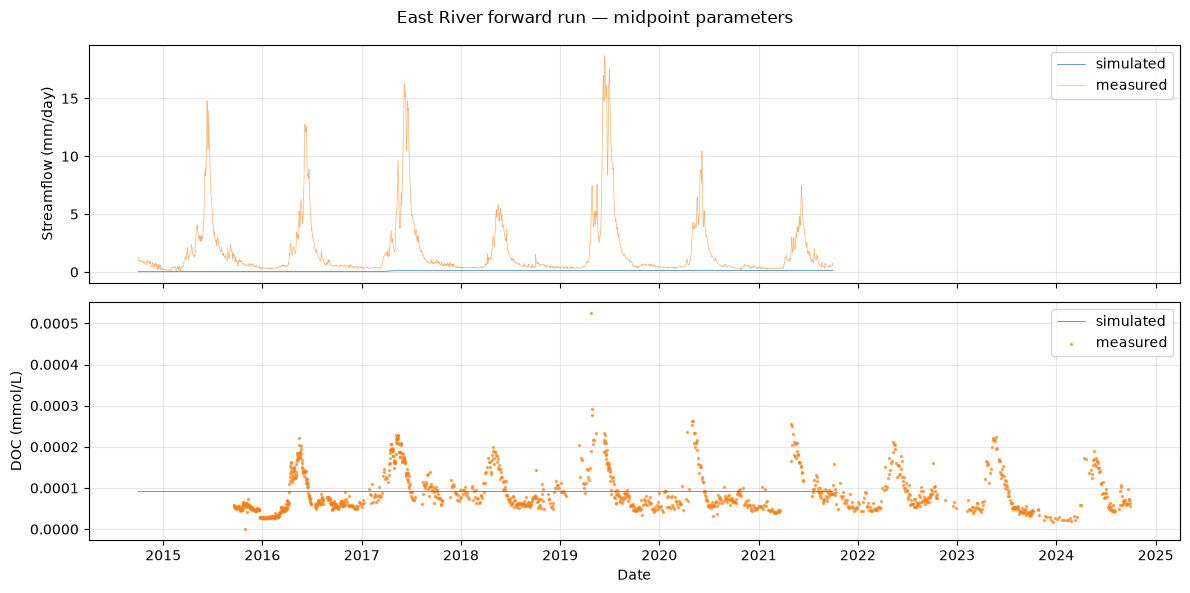

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(window, q_sim, linewidth=0.5, label="simulated")
axes[0].plot(
    window, site.loc[window, "q_meas"], linewidth=0.5, alpha=0.6, label="measured"
)
axes[0].set_ylabel("Streamflow (mm/day)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(window, doc_riv, linewidth=0.5, label="simulated")
axes[1].scatter(doc.index, doc["DOC"], s=2, c="C1", alpha=0.6, label="measured")
axes[1].set_ylabel("DOC (mmol/L)")
axes[1].set_xlabel("Date")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("East River forward run — midpoint parameters")
plt.tight_layout()

## 8. Objectives

The batched runner computes the same objective functions as the
calibration pipeline: KGE, log-KGE, NSE, log-NSE, bias, Spearman ρ, R²
for both streamflow and river DOC.

In [16]:
hydro_obj = out.hydro_objectives[0]
doc_obj = out.rt_doc_objectives[0]

obj_df = pd.DataFrame({"streamflow": hydro_obj, "river_DOC": doc_obj})
obj_df

,streamflow,river_DOC
kge,-0.637575,-0.699712
log_kge,-28.395230,-0.699706
nse,-0.372928,-0.000009
log_nse,-3.347642,-0.000010
bias,-0.947223,0.000850
spearman_rho,0.177099,-0.535613
r_squared,0.009245,0.140196


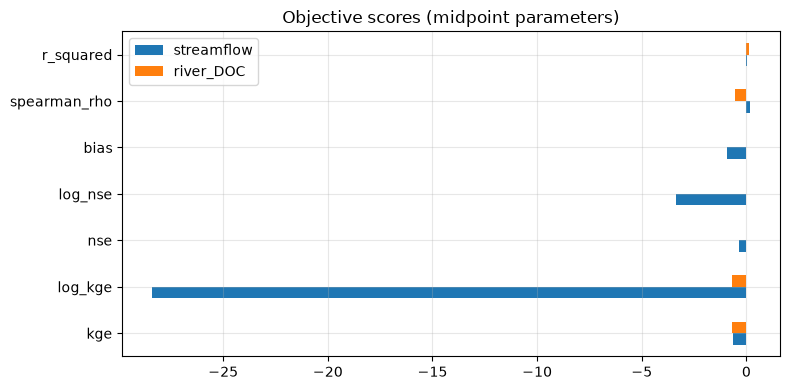

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
obj_df.plot.barh(ax=ax)
ax.set_title("Objective scores (midpoint parameters)")
ax.grid(True, alpha=0.3)
plt.tight_layout()

## 9. Override parameters with a CSV

Any subset of the 85 columns can be supplied via `--params`;
columns not in the CSV fall back to the midpoint values above.

In [18]:
# Example: override two hydrology parameters, leave the rest at midpoints
override = pd.DataFrame({"surface_hs.fc": [200.0], "deep_rp.k": [0.01]})

filled = override.reindex(columns=names).fillna(Series(params, index=names))
params_override = filled[names].to_numpy(dtype=np.float64).ravel()

fc_i = names.index("surface_hs.fc")
k_i = names.index("deep_rp.k")
print(
    f"Override: surface_hs.fc={params_override[fc_i]}, deep_rp.k={params_override[k_i]}"
)
print("(All other 83 parameters unchanged from midpoints)")

Override: surface_hs.fc=200.0, deep_rp.k=0.01
(All other 83 parameters unchanged from midpoints)


In [ ]:
started = time.perf_counter()
out2 = run_hydro_rt_batched(params_override.reshape(1, -1), config, device, dtype)
wall2 = time.perf_counter() - started

q_sim2 = Series(out2.q_sim[0].detach().cpu().numpy(), index=window, name="q_sim")
doc_riv2 = Series(out2.doc_riv[0].detach().cpu().numpy(), index=window, name="doc_riv")
print(f"Done in {wall2:.1f}s")
print(
    f"Streamflow mean: {float(q_sim2.mean()):.4f} mm/day  (was {float(q_sim.mean()):.4f})"
)
print(
    f"DOC mean:        {float(doc_riv2.mean()):.6f} mmol/L  (was {float(doc_riv.mean()):.6f})"
)

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(window, q_sim, linewidth=0.5, alpha=0.5, label="midpoint")
axes[0].plot(window, q_sim2, linewidth=0.5, label="override")
axes[0].set_ylabel("Streamflow (mm/day)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(window, doc_riv, linewidth=0.5, alpha=0.5, label="midpoint")
axes[1].plot(window, doc_riv2, linewidth=0.5, label="override")
axes[1].set_ylabel("DOC (mmol/L)")
axes[1].set_xlabel("Date")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Effect of parameter override")
plt.tight_layout()

## 10. Save outputs

Two files are written: a CSV of daily `q_sim` + `doc_riv`, and a pickle
containing the full payload (window, series, objectives, run time).

In [ ]:
OUT_DIR = Path("../scripts/outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

tag = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
results = {
    "window": window,
    "q_sim": q_sim,
    "doc_riv": doc_riv,
    "hydro_objectives": hydro_obj,
    "rt_doc_objectives": doc_obj,
    "run_seconds": wall,
}

csv_path = OUT_DIR / f"east_river_{tag}.csv"
pkl_path = OUT_DIR / f"east_river_{tag}.pkl"
pd.concat([q_sim, doc_riv], axis=1).to_csv(csv_path, float_format="%.6f")
with open(pkl_path, "wb") as f:
    pickle.dump(results, f)

print(f"Saved: {csv_path}")
print(f"Saved: {pkl_path}")

In [ ]:
print("\nDone.")